# 02 · Churn Modelling
Model comparison, evaluation and explainability. Training is done by `src/train_model.py`; this notebook reproduces and explains the results.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sqlalchemy import text
from src.config import get_engine, SNAPSHOT_DATE
engine = get_engine()
sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a"])
pd.set_option("display.float_format", "{:,.2f}".format)
import json, joblib, shap
from sklearn.metrics import classification_report, roc_auc_score
from src.config import MODELS_DIR
from src.train_model import NUMERIC, CATEGORICAL, candidate_models

## 1. Training data
One row per active customer at **30 Jun 2026**; label = no order in the following 90 days.

In [2]:
with engine.begin() as c:
    c.execute(text("UPDATE feature_params SET snap = :s"), {"s": SNAPSHOT_DATE})
    df = pd.read_sql("SELECT * FROM customer_features", c)
df[NUMERIC + CATEGORICAL + ["churned"]].head()

,age,tenure_days,recency_days,frequency_365d,orders_last_90d,orders_prev_90d,order_trend,monetary_365d,avg_order_value,lifetime_orders,...,avg_satisfaction,sessions_last_90d,sessions_prev_90d,session_trend,avg_session_minutes,gender,state,acquisition_channel,favourite_category,churned
0,64.00,274,25,4,1,0,1,"10,627.15","2,656.79",4,...,NaN,9,13,-4,5.90,Male,Maharashtra,Social Media,Sports & Fitness,False
1,54.00,98,24,1,1,0,1,"1,007.30","1,007.30",1,...,NaN,4,3,1,6.05,Male,Maharashtra,Referral,Home & Kitchen,True
2,48.00,135,58,3,2,1,1,"2,594.10",864.70,3,...,2.00,6,11,-5,7.85,Male,Madhya Pradesh,Email,Beauty,False
3,18.00,630,189,2,0,0,0,"9,298.60","9,298.60",2,...,NaN,3,6,-3,2.75,Male,Kerala,Paid Search,Electronics,False
4,37.00,428,135,11,0,1,-1,"13,601.10","1,575.19",19,...,2.40,6,14,-8,3.65,Male,Maharashtra,Social Media,Toys,False


## 2. Model comparison (5-fold CV)

In [3]:
metrics = json.loads((MODELS_DIR / "metrics.json").read_text())
pd.DataFrame(metrics["model_comparison"])

,model,cv_roc_auc,cv_roc_auc_std,test_roc_auc,test_pr_auc
0,Random Forest,0.85,0.00,0.86,0.86
1,XGBoost,0.84,0.00,0.86,0.86
2,Logistic Regression,0.84,0.01,0.86,0.85


## 3. Test-set performance of the selected model

In [4]:
test = pd.read_csv(MODELS_DIR / "test_predictions.csv")
print(metrics["best_model"], "| threshold", round(metrics["threshold"], 2))
print(classification_report(test["y_true"], test["churn_probability"] >= metrics["threshold"], target_names=["stayed", "churned"]))
print("ROC-AUC", round(roc_auc_score(test["y_true"], test["churn_probability"]), 3), "| top-decile lift", round(metrics["top_decile_lift"], 2))

Random Forest | threshold 0.45
              precision    recall  f1-score   support

      stayed       0.80      0.79      0.80       738
     churned       0.74      0.75      0.75       577

    accuracy                           0.78      1315
   macro avg       0.77      0.77      0.77      1315
weighted avg       0.78      0.78      0.78      1315

ROC-AUC 0.859 | top-decile lift 2.28


In [5]:
# Calibration-style check: actual churn rate by predicted-probability decile
test["decile"] = pd.qcut(test["churn_probability"], 10, labels=False) + 1
test.groupby("decile").agg(customers=("y_true", "size"), avg_pred=("churn_probability", "mean"), actual=("y_true", "mean"))

,customers,avg_pred,actual
decile,,,
1,132,0.09,0.05
2,131,0.16,0.15
3,132,0.23,0.18
4,131,0.29,0.21
5,132,0.37,0.33
6,131,0.45,0.32
7,131,0.54,0.53
8,132,0.69,0.70
9,131,0.90,0.92


## 4. Explainability (SHAP)

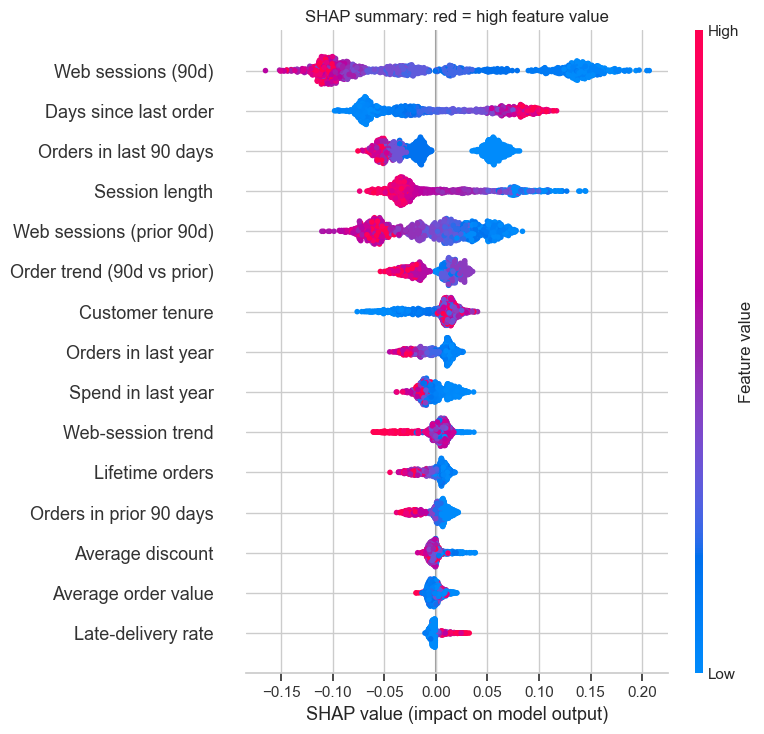

In [6]:
s = joblib.load(MODELS_DIR / "shap_sample.pkl")
X = s["X"].copy(); X.columns = s["labels"]
shap.summary_plot(s["shap_values"], X, max_display=15, show=False)
plt.title("SHAP summary: red = high feature value"); plt.tight_layout()

## 5. Scored customer base (30 Sep 2026)

In [7]:
preds = pd.read_sql("SELECT * FROM churn_predictions", engine)
preds.groupby("risk_tier").agg(customers=("customer_id", "count"), avg_probability=("churn_probability", "mean"))

,customers,avg_probability
risk_tier,,
High,2252,0.85
Low,2700,0.18
Medium,2394,0.43


In [8]:
preds["top_driver"].value_counts().head(10)

top_driver
Web sessions (90d)            2414
Customer tenure                983
Web sessions (prior 90d)       696
Session length                 692
Days since last order          594
Order trend (90d vs prior)     418
Orders in last 90 days         234
Orders in last year            199
Late-delivery rate             190
Spend in last year             155
Name: count, dtype: int64

## Conclusions
- All three models land around **0.84–0.86 ROC-AUC**; the Random Forest has the best cross-validated AUC and is selected.
- **Engagement** (web sessions, recency, recent orders) is the strongest signal, followed by **experience** (delivery delays, support satisfaction) and **acquisition channel**.
- The riskiest decile is almost entirely true churners, so a retention budget aimed at the top of the list is used efficiently.